# IS 327 - Homework 4
In this homework, you will practice two clustering methods: agglomerative clustering (with different linkages) and DBSCAN. We will work with data that have labels. However, remember, clustering methods only has the job to recover some underlying spatial distribution or connectivity patterns. These patterns do not necessarily correponds to ground truth labels. And in reality, you won't have the labels

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import load_wine

## 1. load datasets

We will use three toy datasets this time: iris, cancer, and wine

In [2]:
iris = load_iris()
cancer = load_breast_cancer()
wine = load_wine()

In [3]:
iris_X = iris.data
iris_y = iris.target

cancer_X = cancer.data
cancer_y = cancer.target

wine_X = wine.data
wine_y = wine.target

## 2. Dimension Reduction

We will use dimension reduction to reduce the X into two dimensions so that we can visualize them and use the reduced data for clustering. I wrote the code for you because we haven't covered dimension reduction yet.

In [4]:
# Dimension reduction with PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=2) # only reduced to two dimensions
pca.fit(iris_X)
iris_X_pca = pca.transform(iris_X)

pca.fit(cancer_X)
cancer_X_pca = pca.transform(cancer_X)

pca.fit(wine_X)
wine_X_pca = pca.transform(wine_X)

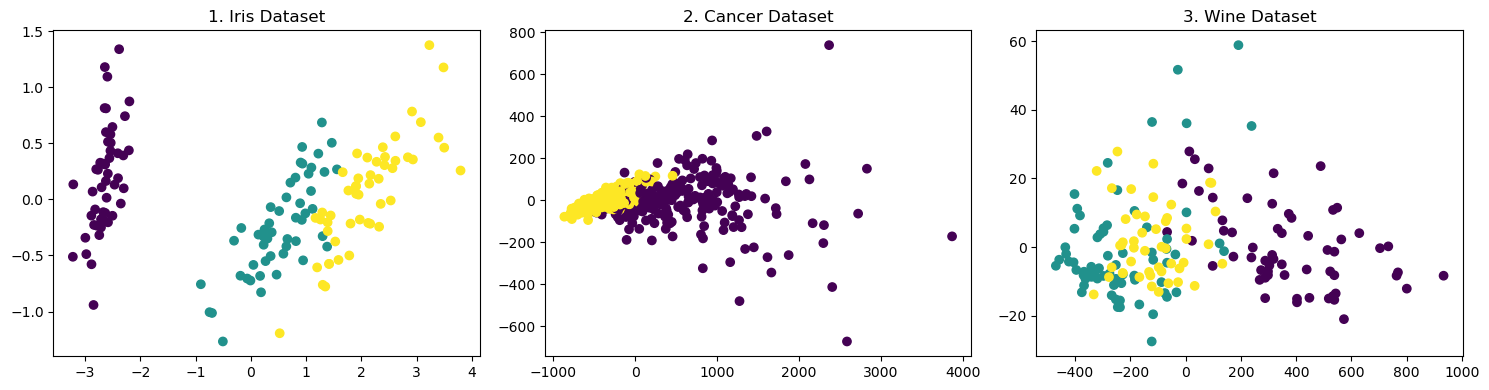

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_y)
axes[0].set_title('1. Iris Dataset')

axes[1].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_y)
axes[1].set_title('2. Cancer Dataset')

axes[2].scatter(wine_X_pca[:,0], wine_X_pca[:,1], c=wine_y)
axes[2].set_title('3. Wine Dataset')

plt.tight_layout()
plt.show()

**TODO 1** (5 pt)

Observe the three plots above. In your opinion, which will be the **easiest** to cluster? Why?

Answer:

1, the Iris Dataset is easiest to cluster since the three distinct section are quite visible. The data has sort of organized itself in the way that it exists, which makes clusering much easier. 

**TODO 2** (5 pt)

Observe the three plots above. In your opinion, which will be the **most difficult** to cluster? Why?

Answer: 3, the Wine Dataset, is the most challenging to cluster since they seem to overlap heavily with little to no boundaries between different categories. It seems that genearlly, the purples is more to the right, the yellow is more towards the middle-left, and green is mostly concentrated to the left. This, however, is not true for every point in each category, meaning this would be most challenging to cluster. 


## 3. Agglomerative Clustering

We know there are four different linkage methods in the AgglomerativeClustering class. We will experiment with some of them in this section. 

### 3.1 Linkage="single"

⚠️ Make sure that you review the class material before attempting this section.

In [6]:
# cluster the iris dataset using AgglomerativeClustering
# set linkage to 'single'

from sklearn.cluster import AgglomerativeClustering
agg_single = AgglomerativeClustering(n_clusters=3, linkage='single')
iris_y_pred_single = agg_single.fit_predict(iris_X)

In [7]:
# TODO 3 (5 pt)

# cluster on the cancer dataset using AgglomerativeClustering
# set linkage to "single"
# make sure the predicted clusters are cancer_y_pred_single

# Code here

from sklearn.cluster import AgglomerativeClustering

agg_cancer_single = AgglomerativeClustering(n_clusters=2, linkage='single')
cancer_y_pred_single = agg_cancer_single.fit_predict(cancer_X)


In [8]:
# TODO 4 (5 pt)

# cluster on the wine dataset using AgglomerativeClustering
# set linkage to 'single'
# make sure the predicted clusters are wine_y_pred_single

# Code here

agg_wine_single = AgglomerativeClustering(n_clusters=3, linkage='single')
wine_y_pred_single = agg_wine_single.fit_predict(wine_X)


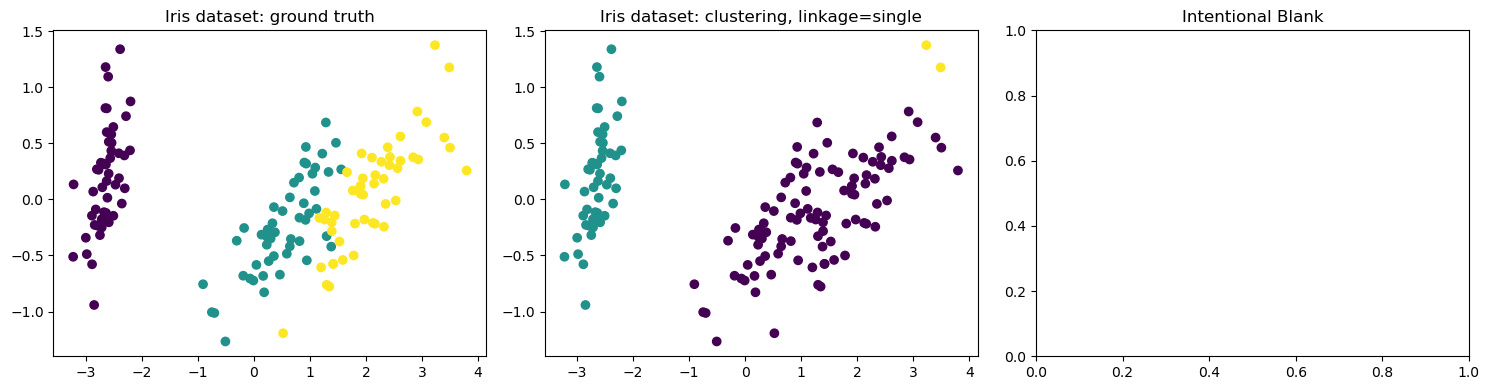

In [9]:
# visualize the clusters along side with the original data

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_y)
axes[0].set_title('Iris dataset: ground truth')

axes[1].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_y_pred_single)
axes[1].set_title('Iris dataset: clustering, linkage=single')

axes[2].set_title("Intentional Blank")

plt.tight_layout()
plt.show()

**TODO 5** (5 pt)

Based on what we learned in class, what do you think posed challenges to the linkage=single method from the **iris dataset**?

Answer: Single linkage can be sensitive to chaining, and in addition, the categories are close to eachother and slightly overlap, which could lead to incorrect merging at times.

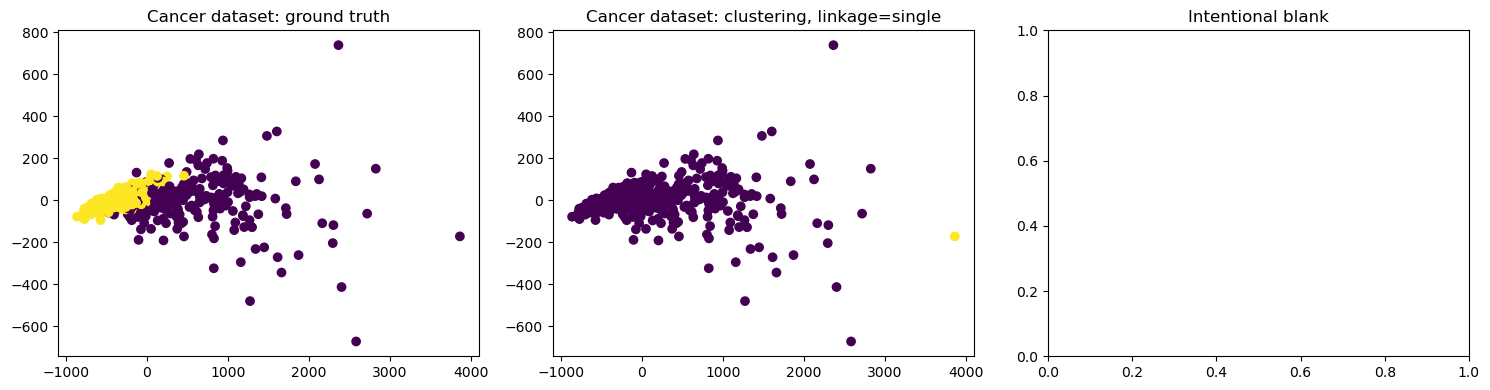

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_y)
axes[0].set_title('Cancer dataset: ground truth')

axes[1].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_y_pred_single)
axes[1].set_title('Cancer dataset: clustering, linkage=single')

axes[2].set_title("Intentional blank")

plt.tight_layout()
plt.show()

**TODO 6** (5 pt)

Based on what we learned in class, what do you think posed challenges to the linkage=single method from the **cancer dataset**?

Answer: This dataset has much more dense regions, as well as more overlapping than the iris dataset. Additionally, it contains more overlapping, so single linkage could merge points incorrectly because of their proximity to eachother rather than actual group structure. This method can be sensitive to noise and outliers as well, which can cause distortion of how clusters are connected.

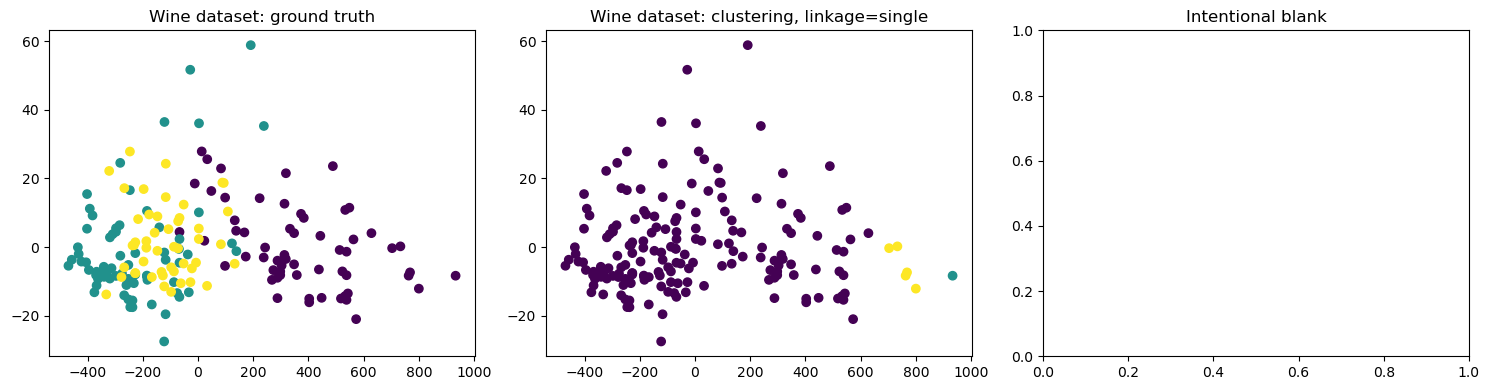

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(wine_X_pca[:,0], wine_X_pca[:,1], c=wine_y)
axes[0].set_title('Wine dataset: ground truth')

axes[1].scatter(wine_X_pca[:,0], wine_X_pca[:,1], c=wine_y_pred_single)
axes[1].set_title('Wine dataset: clustering, linkage=single')

axes[2].set_title("Intentional blank")

plt.tight_layout()
plt.show()

**TODO 7** (5 pt)

Based on what we learned in class, what do you think posed challenges to the linkage=single method from the **wine dataset**?

Answer: I think it is that there is a lot of overlapping and uneven clustering structure, in addition to how clusters are merged, is a recipe for a lot of points ending up into a single massive cluster, oftentimes incorrectly. 

### 3.2 Linkage='ward'

⚠️ Make sure that you review the class material before attempting this section.

In [12]:
# cluster the iris dataset

from sklearn.cluster import AgglomerativeClustering
agg_single = AgglomerativeClustering(n_clusters=3, linkage='ward')
iris_y_pred_ward = agg_single.fit_predict(iris_X)


In [13]:
# TODO 8 (5 pt)

# cluster on the cancer dataset using AgglomerativeClustering
# set linkage to 'ward'
# make sure the predicted clusters are named 'cancer_y_pred_ward'

# Code here
agg_cancer_ward = AgglomerativeClustering(n_clusters=2, linkage='ward')
cancer_y_pred_ward = agg_cancer_ward.fit_predict(cancer_X)

In [14]:
# TODO 9 (5 pt)

# cluster on the wine dataset using AgglomerativeClustering
# set linkage to 'ward'
# make sure the predicted clusters are named "wine_y_pred_ward'

# Code here
agg_wine_ward = AgglomerativeClustering(n_clusters=3, linkage='ward')
wine_y_pred_ward = agg_wine_ward.fit_predict(wine_X)

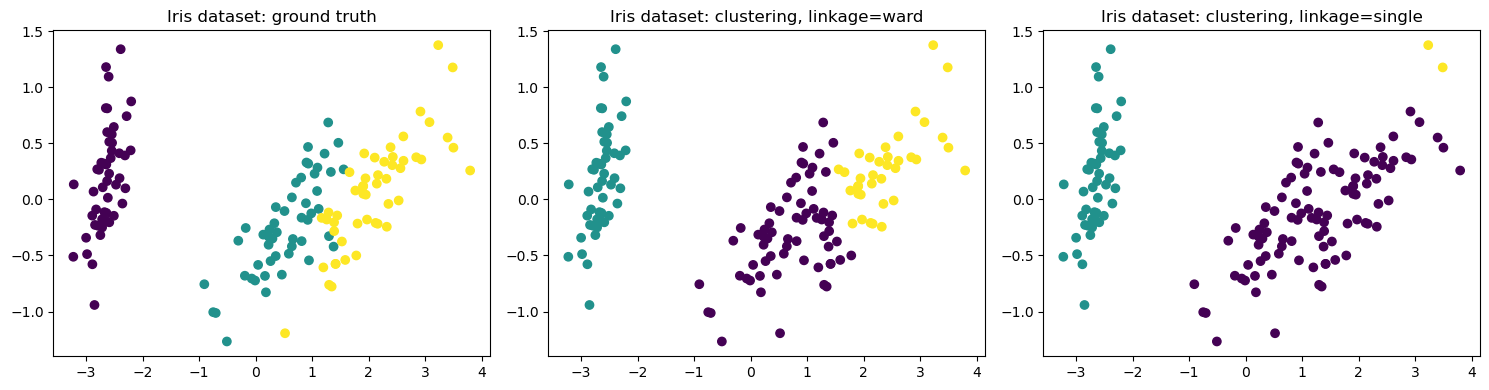

In [15]:
# visualizations

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_y)
axes[0].set_title('Iris dataset: ground truth')

axes[1].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_y_pred_ward)
axes[1].set_title('Iris dataset: clustering, linkage=ward')

axes[2].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_y_pred_single)
axes[2].set_title('Iris dataset: clustering, linkage=single')

plt.tight_layout()
plt.show()

**TODO 10** (5 pt)

Based on what we learned in class, do you notice any change from linkage=single to linkage=ward in the **iris dataset**? Why?

Answer: Ward linkage seems to have created a more compact/balanced set of clusters, yielding less variance with each cluster. This different method has improved the clustering compared to single linkage since that method was distorted by the long chaining and clusters were incorrectly merged together.

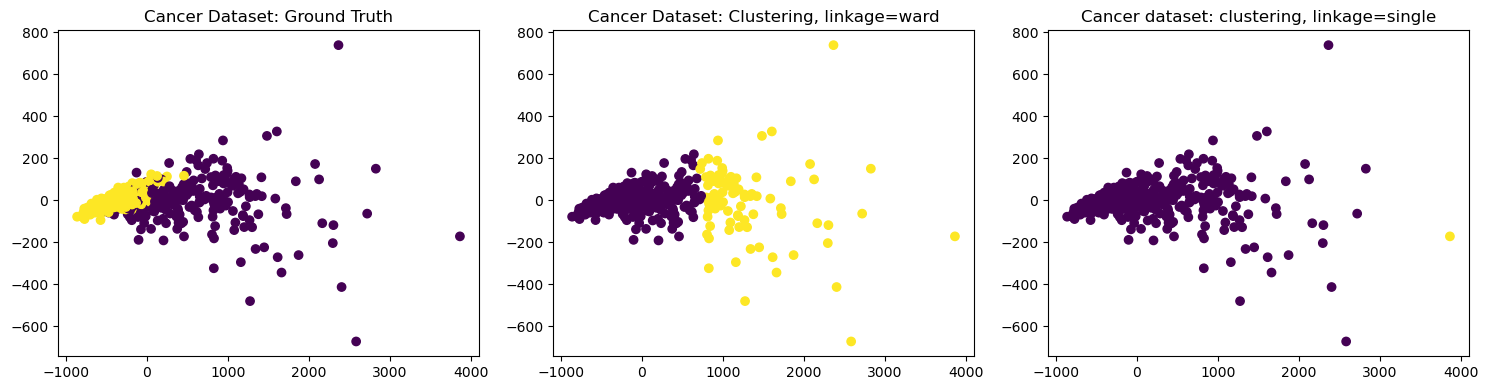

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_y)
axes[0].set_title('Cancer Dataset: Ground Truth')

axes[1].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_y_pred_ward)
axes[1].set_title('Cancer Dataset: Clustering, linkage=ward')

axes[2].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_y_pred_single)
axes[2].set_title('Cancer dataset: clustering, linkage=single')

plt.tight_layout()
plt.show()

**TODO 11** (5 pt)

Based on what we learned in class, do you notice any change from linkage=single to linkage=ward in the **cancer dataset**? Why?

Answer: Ward linkage does a far better job of separating distinct main clusters compared to the single linkage, which merges too many points together. It seems this is the case becasue Ward linkage minimizes total variance within the clusters. Single linkage just uses nearest neighbors, which causes those long chains and poor separation with overlapping, dense data.

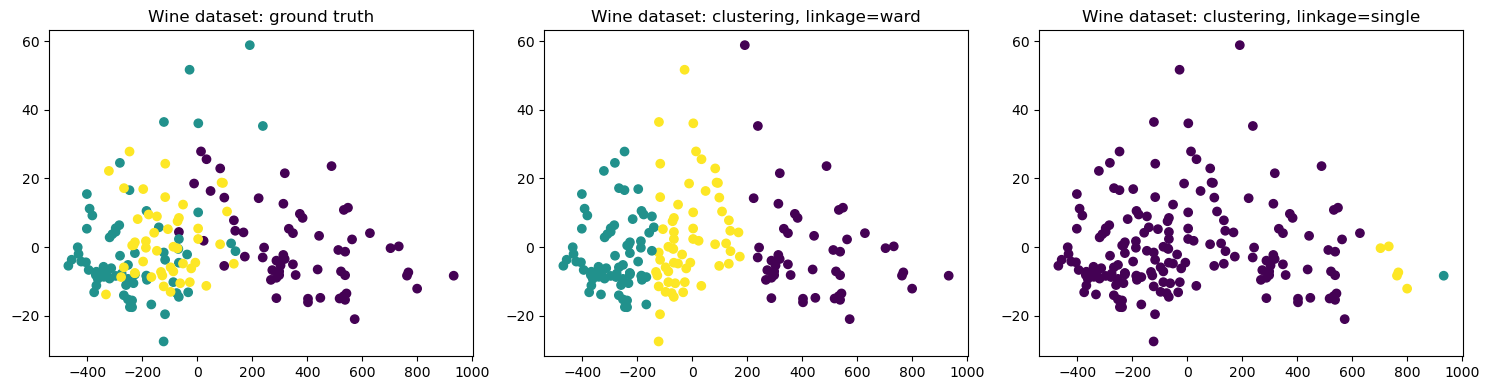

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(wine_X_pca[:,0], wine_X_pca[:,1], c=wine_y)
axes[0].set_title('Wine dataset: ground truth')

axes[1].scatter(wine_X_pca[:,0], wine_X_pca[:,1], c=wine_y_pred_ward)
axes[1].set_title('Wine dataset: clustering, linkage=ward')

axes[2].scatter(wine_X_pca[:,0], wine_X_pca[:,1], c=wine_y_pred_single)
axes[2].set_title('Wine dataset: clustering, linkage=single')

plt.tight_layout()
plt.show()

**TODO 12** (5 pt)

Based on what we learned in class, do you notice any change from linkage=single to linkage=ward in the **wine dataset**? Why?

Answer: Yes, this is also a significantly better clustering compared to the single linkage. This verison handles the overlapping regions much better with tighter clusters with less variance, rather than those long chains in single linkage. The clusters are more meaningful under ward linkage despite the challenging nature of the wine dataset. 

## 4. DBSCAN



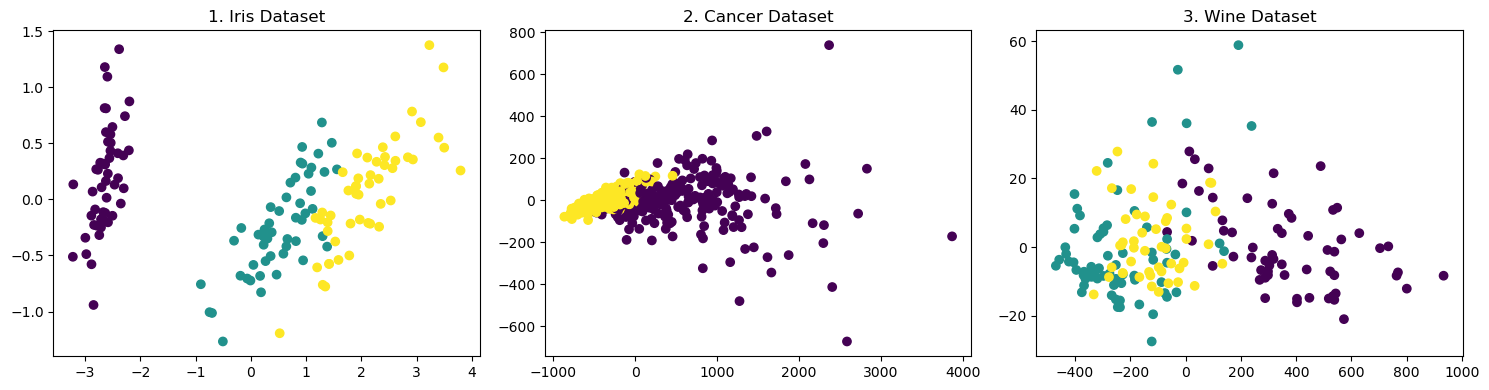

In [18]:
# revisualize the three datasets
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_y)
axes[0].set_title('1. Iris Dataset')

axes[1].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_y)
axes[1].set_title('2. Cancer Dataset')

axes[2].scatter(wine_X_pca[:,0], wine_X_pca[:,1], c=wine_y)
axes[2].set_title('3. Wine Dataset')

plt.tight_layout()
plt.show()

**TODO 13** (5 pt)

DBSCAN is a density-based clustering method. Observe the three datasets' visualizations, and tell me whether their density distribution can **facilitate** DBSCAN's detection of clusters (Y/N)? Also provide reasons. Otherwise you won't get the full points. 

Answers:

Iris dataset (Y/N): Yes
The clusters are compact and well separated, which works well with DBSCAN's density-based approach. It should be able to identify clusters based on local point density. 

Cancer dataset (Y/N): No
The data is unevenly dense and overlaps quite a bit. This makes it hard for DBSCAN to define meaningful clusters. DBSCAN could then either group everything together or misclassify points as noise. 

Wine dataset (Y/N): No
There is no clear separation of clusters and they are not compact. the points are also spread out inconsistently. This method struggles to find stable density thresholds across the full distribution, leading to these subpar results. 


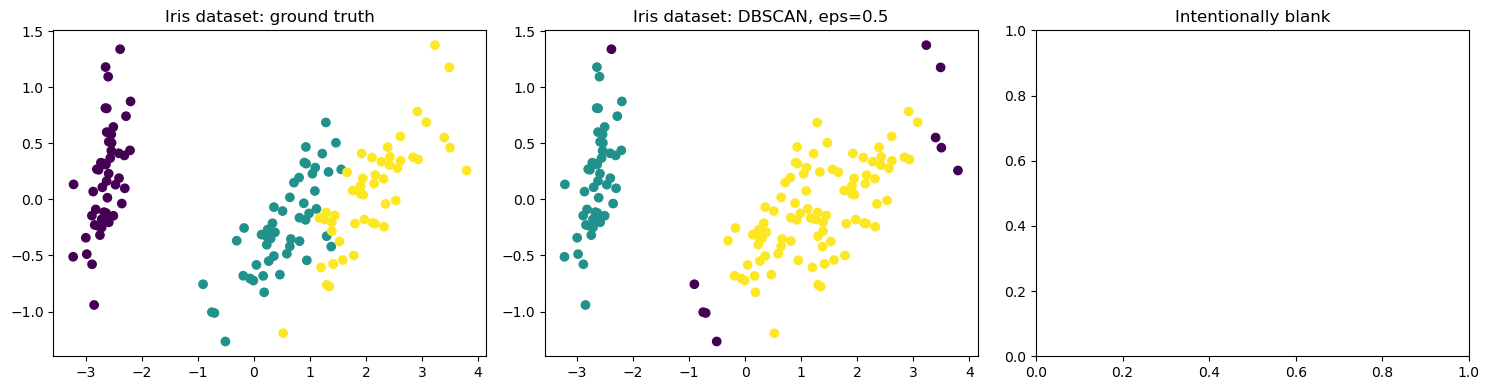

In [19]:
# perform DBSCAN on the iris_X_PCA

from sklearn.cluster import DBSCAN
iris_dbscan = DBSCAN(eps=0.5, min_samples=10).fit(iris_X_pca)

# visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_y)
axes[0].set_title('Iris dataset: ground truth')

axes[1].scatter(iris_X_pca[:,0], iris_X_pca[:,1], c=iris_dbscan.labels_)
axes[1].set_title('Iris dataset: DBSCAN, eps=0.5')

axes[2].set_title('Intentionally blank')

plt.tight_layout()
plt.show()

**TODO 14** (5 pt)

Recall the class materials. What does the visualization tell you about DBSCAN?

Answer: This method was able to identify two distinct clusters and marked points as noise. However, it failed to really detect the third true cluster. The following result shows that it handles dense groups well, but may under-cluster when clusters vary in density and/or spacing. 

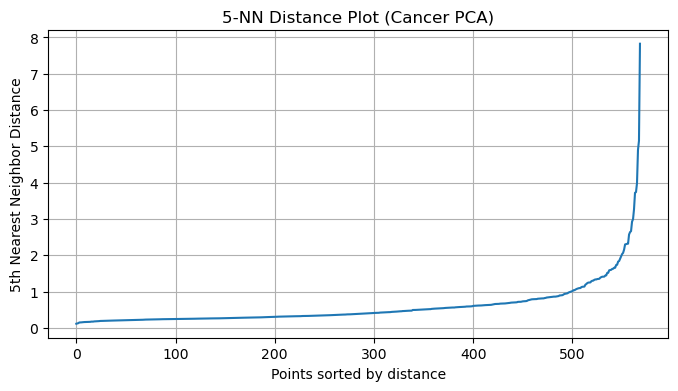

In [41]:
# TODO 15 (5 pt)
# now it's your turn. Perform DBSCAN on the cancer dataset and produce the same visualization comparison as I showed above.
# feel free to try a few different parameter settings, such as giving eps other values than 0.5

# Code here

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np

scaler = StandardScaler()
cancer_X_scaled = scaler.fit_transform(cancer_X)


pca = PCA(n_components=2)
cancer_X_pca = pca.fit_transform(cancer_X_scaled)


neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(cancer_X_pca)
distances, indices = neighbors_fit.kneighbors(cancer_X_pca)


distances = np.sort(distances[:, 4])
plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.title("5-NN Distance Plot (Cancer PCA)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.grid(True)
plt.show()


cancer_dbscan = DBSCAN(eps=0.6, min_samples=6).fit(cancer_X_pca)


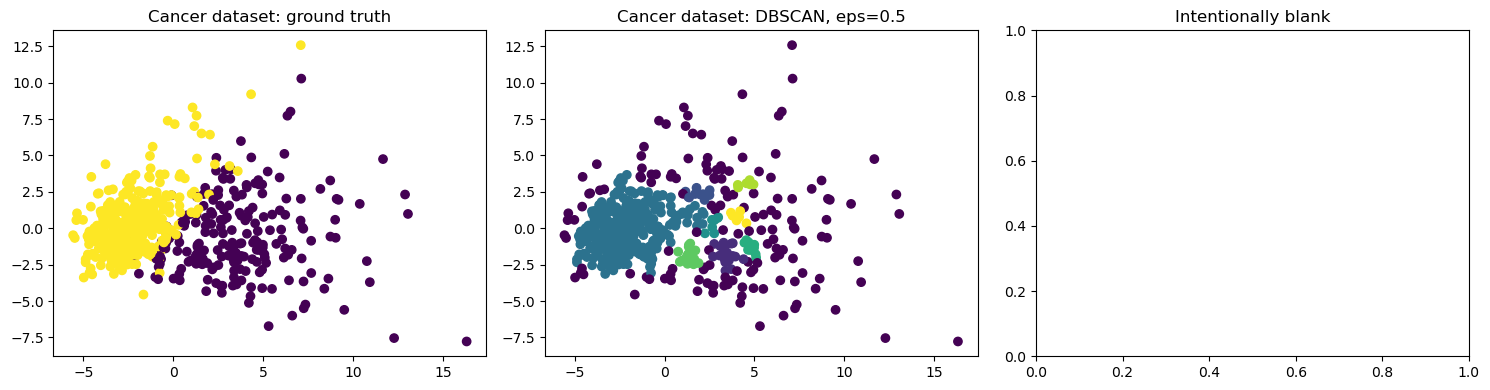

In [42]:
# visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_y)
axes[0].set_title('Cancer dataset: ground truth')

axes[1].scatter(cancer_X_pca[:,0], cancer_X_pca[:,1], c=cancer_dbscan.labels_)
axes[1].set_title('Cancer dataset: DBSCAN, eps=0.5')

axes[2].set_title('Intentionally blank')

plt.tight_layout()
plt.show()

In [55]:
# TODO 16 (5 pt)
# Perform DBSCAN on the wine dataset and produce the same visualization comparison as I showed above.
# feel free to try a few different parameter settings, such as giving eps other values than 0.5

# Code here

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


scaler = StandardScaler()
wine_X_scaled = scaler.fit_transform(wine_X)


pca = PCA(n_components=2)
wine_X_pca = pca.fit_transform(wine_X_scaled)


wine_dbscan = DBSCAN(eps=0.5, min_samples=6).fit(wine_X_pca)


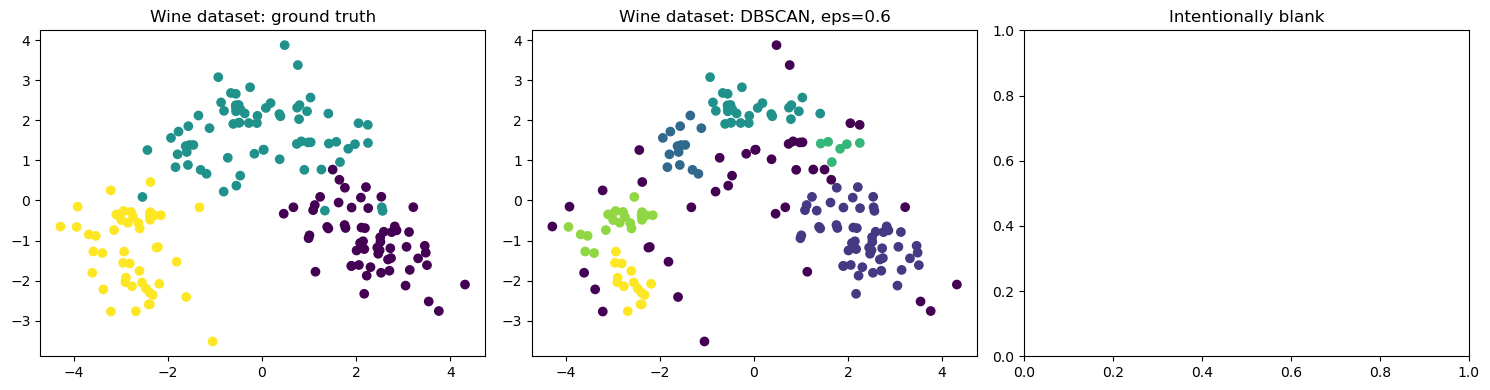

In [56]:
# visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(wine_X_pca[:, 0], wine_X_pca[:, 1], c=wine_y)
axes[0].set_title('Wine dataset: ground truth')

axes[1].scatter(wine_X_pca[:, 0], wine_X_pca[:, 1], c=wine_dbscan.labels_)
axes[1].set_title('Wine dataset: DBSCAN, eps=0.6')

axes[2].set_title('Intentionally blank')
plt.tight_layout()
plt.show()


## 5. Clustering the entire dataset and CH index

Again, I emphasize that clustering do not need to recover the labels. However, when they do, it is nice to confirm that the features are (collectively) correlated to the labels. We saw that the iris dataset performed better than the other two datasets. A drawback of what we have done so far is that we reduced the full X to 2D, thus loosing a lot of information. The cancer and wine dataset may well be separable if all dimensions are considered. However, it will be difficult for us to visually check the results. In order to assess the quality of clustering, we will use the CH index.

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html

https://en.wikipedia.org/wiki/Calinski%E2%80%93Harabasz_index

I will demo with k-means and the iris dataset (well separable, so its CH index will be high). Please try two more algorithms and apply them to wine and cancer dataset to see whether they were cluster

See all possible clustering algorithms @ https://scikit-learn.org/stable/api/sklearn.cluster.html


In [57]:
# demo with the iris dataset and k-means

from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

kmeans = KMeans(n_clusters=3) 
kmeans.fit(iris_X) 

ch_score_iris_kmeans = calinski_harabasz_score(iris_X, kmeans.labels_)

print("The CH index is: {:.4f}".format(ch_score_iris_kmeans))

C:\Users\arial\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\arial\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


The CH index is: 561.6278


**TODO 17** (5 pt)

Apply one clustering algorithm to cancer_X and evaluate with CH index

Answer here: 

My choice of clustering algorithm #1 is: Agglomerative Clustering with 3 clusters

The resulting CH index is: 468.6576

In [69]:
# code here

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import calinski_harabasz_score

agglo = AgglomerativeClustering(n_clusters=3)  
agglo_labels = agglo.fit_predict(cancer_X_pca)

ch_score_agglo = calinski_harabasz_score(cancer_X_pca, agglo_labels)
print("The CH index is: {:.4f}".format(ch_score_agglo))



The CH index is: 468.6576


**TODO 18** (5 pt)

Apply a second clustering algorithm to cancer_X and evaluate with CH index

Answer here: 

My choice of clustering algorithm #2 is:KMeans

The resulting CH index is: 507.5611

In [60]:
# code here
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(cancer_X_pca)
ch_score_kmeans = calinski_harabasz_score(cancer_X_pca, kmeans_labels)

print("The CH index for KMeans is: {:.4f}".format(ch_score_kmeans))



C:\Users\arial\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\arial\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


The CH index for KMeans is: 507.5611


**TODO 19** (5 pt)

Apply one clustering algorithm to wine_X and evaluate with CH index

Answer here: 

My choice of clustering algorithm #1 is: KMeans

The resulting CH index is: 344

In [68]:
# code here

from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
wine_X_scaled = scaler.fit_transform(wine_X)

pca = PCA(n_components=2)
wine_X_pca = pca.fit_transform(wine_X_scaled)

kmeans = KMeans(n_clusters=3, random_state=42)
wine_kmeans_labels = kmeans.fit_predict(wine_X_pca)

ch_score_kmeans_wine = calinski_harabasz_score(wine_X_pca, wine_kmeans_labels)
print("The CH index for KMeans (wine dataset) is: {:.4f}".format(ch_score_kmeans_wine))


C:\Users\arial\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\arial\miniconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


The CH index for KMeans (wine dataset) is: 344.7926


**TODO 20** (5 pt)

Apply a second clustering algorithm to wine_X and evaluate with CH index

Answer here: 

My choice of clustering algorithm #2 is: Agglomerative Clustering

The resulting CH index is: 341

In [67]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import calinski_harabasz_score

agglo = AgglomerativeClustering(n_clusters=3)
wine_agglo_labels = agglo.fit_predict(wine_X_pca)

ch_score_agglo_wine = calinski_harabasz_score(wine_X_pca, wine_agglo_labels)
print("The CH index for Agglomerative Clustering (wine dataset) is: {:.4f}".format(ch_score_agglo_wine))


The CH index for Agglomerative Clustering (wine dataset) is: 341.0582


## 5. Conclusion
Congratulations! This is the last homework if you do not plan to do the bonus homework. I will start to grade HW4 on **May 7**. The bonus HW is due on **May 15** (no extension). If you need the grades of HW4 to decide whether you should do the bonus HW, please email me after you submitting HW4, and I will prioritize your grading. Again, the bonus homework will only bring your total grade to 340/400 (85%). Based on the average of previous HWs, I think most of you do not need it. 

## References & generative AI usage declaration




Generative AI usage: Much of the coding and it informed the information I used for some of the short answer todos.  